<a href="https://colab.research.google.com/github/adriennie/vllm-lora-extension/blob/main/lora_peft_rank_ablation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# --- BLOCK 1: Environment Setup & Version Pinning ---
import os
import sys
import importlib.metadata
import subprocess

# Upgrade torchao to satisfy PEFT requirements alongside transformers and peft
!pip install -q --upgrade pip
!pip install -q "torchao>=0.16.0" transformers datasets peft accelerate bitsandbytes pandas matplotlib seaborn pynvml

import torch
import pandas as pd
import pynvml

# Pin and record exact runtime versions to lora_run_metadata.csv
packages = ['torch', 'transformers', 'peft', 'datasets', 'accelerate', 'bitsandbytes', 'pynvml', 'torchao']
version_data = {
    "Package": packages,
    "Version": [importlib.metadata.version(pkg) for pkg in packages],
    "CUDA_Version": torch.version.cuda,
    "GPU_Device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
}

df_metadata = pd.DataFrame(version_data)
df_metadata.to_csv("lora_run_metadata.csv", index=False)
print("[CHECKPOINT 1] LoRA runtime versions pinned and saved to 'lora_run_metadata.csv'.")
print(df_metadata)

[CHECKPOINT 1] LoRA runtime versions pinned and saved to 'lora_run_metadata.csv'.
        Package       Version CUDA_Version GPU_Device
0         torch  2.11.0+cu130         13.0   Tesla T4
1  transformers        5.18.0         13.0   Tesla T4
2          peft        0.21.1         13.0   Tesla T4
3      datasets         4.8.5         13.0   Tesla T4
4    accelerate        1.15.0         13.0   Tesla T4
5  bitsandbytes        0.50.2         13.0   Tesla T4
6        pynvml        13.0.1         13.0   Tesla T4
7       torchao        0.18.0         13.0   Tesla T4


In [6]:
# --- BLOCK 2: Background pynvml Memory Profiler Thread ---
import time
import threading

class LoRAVRAMMonitor(threading.Thread):
    def __init__(self, interval=0.05):
        super().__init__()
        self.interval = interval
        self.max_vram_mb = 0.0
        self.running = True
        pynvml.nvmlInit()
        self.handle = pynvml.nvmlDeviceGetHandleByIndex(0)

    def run(self):
        while self.running:
            info = pynvml.nvmlDeviceGetMemoryInfo(self.handle)
            used_mb = info.used / (1024 ** 2)
            if used_mb > self.max_vram_mb:
                self.max_vram_mb = used_mb
            time.sleep(self.interval)

    def stop(self):
        self.running = False
        self.join()
        pynvml.nvmlShutdown()
        return self.max_vram_mb

In [8]:
# --- BLOCK 3: Systematic Rank Ablation & Training Engine ---
from transformers import AutoModelForCausalLM, AutoTokenizer, TrainingArguments, Trainer
from peft import LoraConfig, get_peft_model, TaskType
from datasets import Dataset
import numpy as np
import time
import torch

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"

print("Loading tokenizer and dataset...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
tokenizer.pad_token = tokenizer.eos_token

raw_data = {
    "text": [
        "Human: Explain LoRA fine-tuning.\nAssistant: Low-Rank Adaptation (LoRA) freezes the pre-trained model weights and injects trainable rank decomposition matrices into the attention layers.",
        "Human: What are the benefits of PEFT?\nAssistant: PEFT significantly reduces memory requirements and storage overhead by only training a small fraction of model parameters.",
        "Human: How does rank selection affect adapters?\nAssistant: Higher rank dimensions capture more complex task nuances at the cost of increased VRAM and parameter footprint."
    ] * 6  # 18 samples total
}
dataset = Dataset.from_dict(raw_data)

def tokenize_function(examples):
    tokenized = tokenizer(examples["text"], padding="max_length", truncation=True, max_length=128)
    # Causal LM training requires labels to match input_ids
    tokenized["labels"] = tokenized["input_ids"].copy()
    return tokenized

tokenized_dataset = dataset.map(tokenize_function, batched=True)

ranks = [4, 8, 16]
seeds = [42, 100]
ablation_results = []

for r in ranks:
    print(f"\n==============================================")
    print(f"  Running PEFT Training Ablation with rank (r)={r}")
    print(f"==============================================")

    for seed in seeds:
        torch.manual_seed(seed)
        torch.cuda.empty_cache()

        # Start background hardware memory monitor
        monitor = LoRAVRAMMonitor(interval=0.05)
        monitor.start()

        # Load base model using modern 'dtype' syntax
        model = AutoModelForCausalLM.from_pretrained(
            MODEL_ID,
            dtype=torch.float16,
            device_map="auto"
        )

        peft_config = LoraConfig(
            task_type=TaskType.CAUSAL_LM,
            inference_mode=False,
            r=r,
            lora_alpha=r * 2,  # Standard scaling heuristic
            lora_dropout=0.05,
            target_modules=["q_proj", "v_proj"]
        )

        model = get_peft_model(model, peft_config)
        trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

        training_args = TrainingArguments(
            output_dir=f"./results_r{r}_seed{seed}",
            per_device_train_batch_size=2,
            num_train_epochs=1,
            learning_rate=2e-4,
            logging_steps=5,
            save_strategy="no",
            report_to="none"
        )

        trainer = Trainer(
            model=model,
            args=training_args,
            train_dataset=tokenized_dataset,
        )

        torch.cuda.synchronize()
        start_time = time.perf_counter()

        trainer.train()

        torch.cuda.synchronize()
        train_duration = time.perf_counter() - start_time

        peak_vram = monitor.stop()

        ablation_results.append({
            "rank": r,
            "seed": seed,
            "trainable_params": trainable_params,
            "train_time_seconds": train_duration,
            "peak_vram_mb": peak_vram
        })

        # Clean up model instance from memory before next trial
        del model, trainer
        torch.cuda.empty_cache()

df_lora_ablation = pd.DataFrame(ablation_results)
df_lora_ablation.to_csv("lora_rank_ablation.csv", index=False)
print("\n[CHECKPOINT 3] LoRA rank ablation completed. Results saved to 'lora_rank_ablation.csv'.")
print(df_lora_ablation)

Loading tokenizer and dataset...


Map:   0%|          | 0/18 [00:00<?, ? examples/s]


  Running PEFT Training Ablation with rank (r)=4


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Step,Training Loss
5,18.035675


...

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Step,Training Loss
5,17.796661


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Step,Training Loss
5,17.792471



[CHECKPOINT 3] LoRA rank ablation completed. Results saved to 'lora_rank_ablation.csv'.
   rank  seed  trainable_params  train_time_seconds  peak_vram_mb
0     4    42            544768            2.088273    10288.1875
1     4   100            544768            1.716439     8474.1875
2     8    42           1089536            1.877037     8474.1875
3     8   100           1089536            1.724299     8474.1875
4    16    42           2179072            1.954278     8474.1875
5    16   100           2179072            1.731583     8474.1875


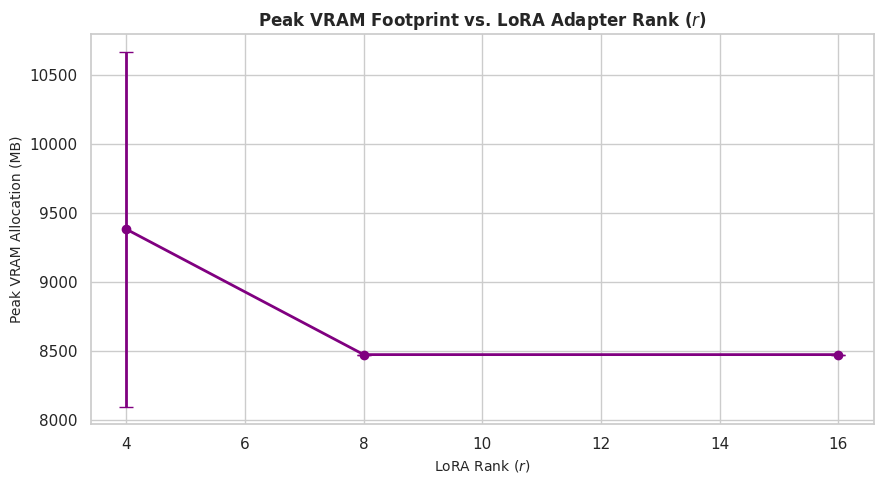

[CHECKPOINT 4] Visualization successfully saved to 'lora_rank_ablation.png'.


In [9]:
# --- BLOCK 4: Error Bar Visualization & Artifact Export ---
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5))

# Aggregate across seeds to calculate mean and standard deviation bounds
df_summary = df_lora_ablation.groupby("rank").agg({
    "peak_vram_mb": ["mean", "std"],
    "train_time_seconds": ["mean", "std"],
    "trainable_params": "first"
}).reset_index()

df_summary.columns = ["rank", "vram_mean", "vram_std", "time_mean", "time_std", "trainable_params"]

plt.errorbar(
    df_summary["rank"],
    df_summary["vram_mean"],
    yerr=df_summary["vram_std"],
    marker='o',
    capsize=5,
    color='purple',
    linewidth=2
)

plt.title("Peak VRAM Footprint vs. LoRA Adapter Rank ($r$)", fontsize=12, fontweight="bold")
plt.xlabel("LoRA Rank ($r$)", fontsize=10)
plt.ylabel("Peak VRAM Allocation (MB)", fontsize=10)
plt.tight_layout()
plt.savefig("lora_rank_ablation.png", dpi=300)
plt.show()
print("[CHECKPOINT 4] Visualization successfully saved to 'lora_rank_ablation.png'.")

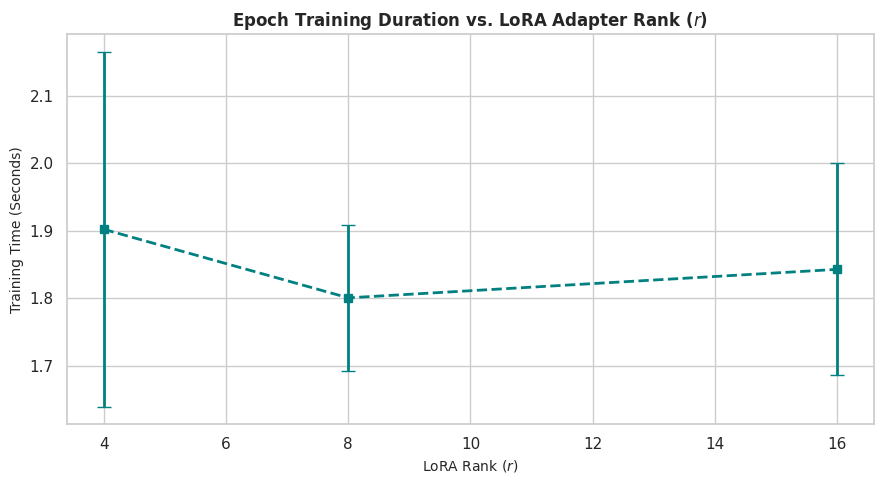

[CHECKPOINT 5] Training time visualization saved to 'lora_training_time_ablation.png'.


In [10]:
# --- BLOCK 5: Training Duration vs. LoRA Rank Visualization ---
plt.figure(figsize=(9, 5))

plt.errorbar(
    df_summary["rank"],
    df_summary["time_mean"],
    yerr=df_summary["time_std"],
    marker='s',
    capsize=5,
    color='teal',
    linewidth=2,
    linestyle='--'
)

plt.title("Epoch Training Duration vs. LoRA Adapter Rank ($r$)", fontsize=12, fontweight="bold")
plt.xlabel("LoRA Rank ($r$)", fontsize=10)
plt.ylabel("Training Time (Seconds)", fontsize=10)
plt.tight_layout()
plt.savefig("lora_training_time_ablation.png", dpi=300)
plt.show()
print("[CHECKPOINT 5] Training time visualization saved to 'lora_training_time_ablation.png'.")

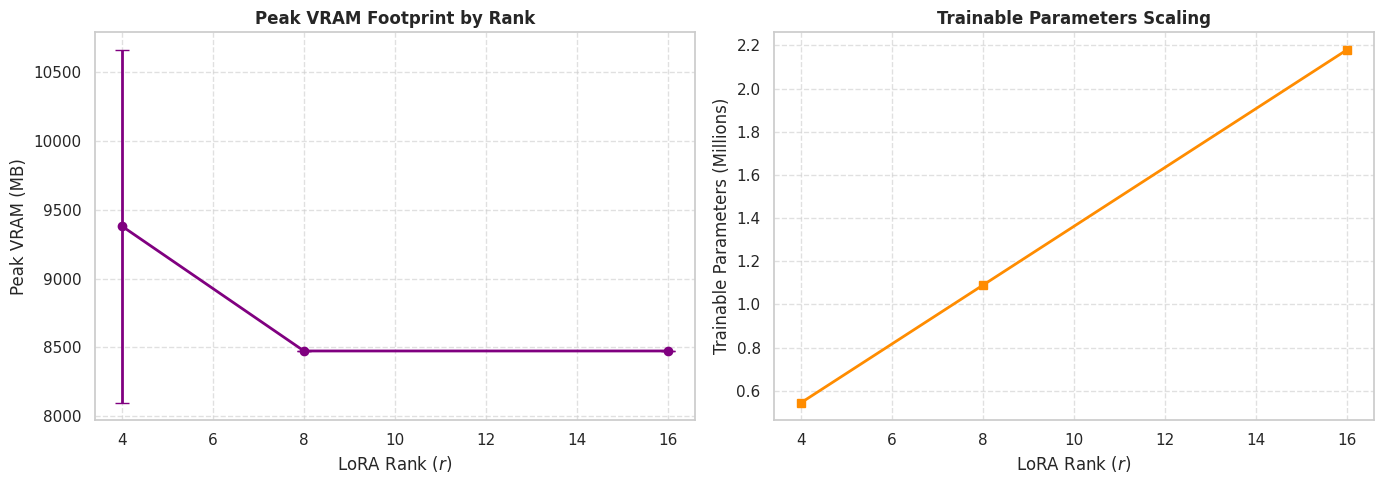

[CHECKPOINT 6] Combined metrics summary saved to 'lora_combined_metrics_summary.png'.


In [11]:
# --- BLOCK 6: Dual-Metric Summary Subplot ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: VRAM Footprint
ax1.errorbar(df_summary["rank"], df_summary["vram_mean"], yerr=df_summary["vram_std"], marker='o', capsize=5, color='purple', linewidth=2)
ax1.set_title("Peak VRAM Footprint by Rank", fontweight="bold")
ax1.set_xlabel("LoRA Rank ($r$)")
ax1.set_ylabel("Peak VRAM (MB)")
ax1.grid(True, linestyle='--', alpha=0.6)

# Plot 2: Trainable Parameters Scaling
ax2.plot(df_summary["rank"], df_summary["trainable_params"] / 1e6, marker='s', color='darkorange', linewidth=2)
ax2.set_title("Trainable Parameters Scaling", fontweight="bold")
ax2.set_xlabel("LoRA Rank ($r$)")
ax2.set_ylabel("Trainable Parameters (Millions)")
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("lora_combined_metrics_summary.png", dpi=300)
plt.show()
print("[CHECKPOINT 6] Combined metrics summary saved to 'lora_combined_metrics_summary.png'.")